# Lab 00-04 · Your Toolchain, End to End

Companion to chapter [00-04](../../chapters/00-04-toolchain-walkthrough.md). Handout: [README.md](README.md). Run all cells; then do the **🔮 Predict** prompts.

In [1]:
import math, shutil, subprocess, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass
print("Python", sys.version.split()[0], "| NumPy", np.__version__)
for tool in ["ngspice", "iverilog", "vvp", "verilator", "gtkwave", "yosys"]:
    print(f"{tool:>10}: {'found' if shutil.which(tool) else 'not found'}")

Python 3.13.18 | NumPy 2.5.4
   ngspice: found
  iverilog: found
       vvp: found
 verilator: found
   gtkwave: not found
     yosys: not found


## Part 1 — Floating point

**🔮 Predict** each printed value before running: `0.1 + 0.2 == 0.3`, the machine epsilon, and `1 - cos(1e-8)`.

In [2]:
print("0.1 + 0.2 == 0.3 ?", 0.1 + 0.2 == 0.3)
print("0.1 + 0.2 - 0.3  =", 0.1 + 0.2 - 0.3)
print("math.isclose(0.1 + 0.2, 0.3) ?", math.isclose(0.1 + 0.2, 0.3))
eps = np.finfo(float).eps
print("machine epsilon  =", eps, "=", 2.0 ** -52)
x = 1e-8
print("1 - cos(x)       =", 1 - math.cos(x), "   (catastrophic cancellation)")
print("2 sin^2(x/2)     =", 2 * math.sin(x / 2) ** 2, "   (stable)")
assert 1 - math.cos(x) == 0.0 and abs(2 * math.sin(x / 2) ** 2 - 5e-17) < 1e-30

0.1 + 0.2 == 0.3 ? False
0.1 + 0.2 - 0.3  = 5.551115123125783e-17
math.isclose(0.1 + 0.2, 0.3) ? True
machine epsilon  = 2.220446049250313e-16 = 2.220446049250313e-16
1 - cos(x)       = 0.0    (catastrophic cancellation)
2 sin^2(x/2)     = 5.0000000000000005e-17    (stable)


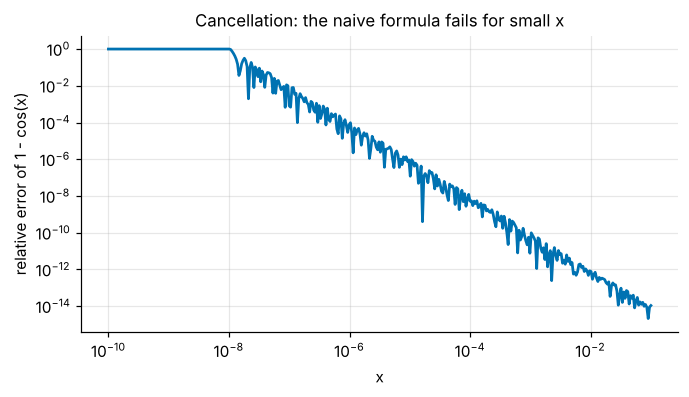

In [3]:
# Where does 1 - cos(x) go wrong? Relative error of the naive form versus x
xs = np.logspace(-10, -1, 400)
naive = 1 - np.cos(xs)
stable = 2 * np.sin(xs / 2) ** 2
rel_err = np.abs(naive - stable) / stable
plt.figure(figsize=(7, 3.5))
plt.loglog(xs, rel_err + 1e-18)
plt.xlabel("x"); plt.ylabel("relative error of 1 - cos(x)")
plt.title("Cancellation: the naive formula fails for small x"); plt.show()

## Part 2 — How SPICE solves a diode circuit: Newton–Raphson

KCL for 5 V → 1 kΩ → diode: $g(V) = (5 - V)/1000 - I_s(e^{V/V_T} - 1) = 0$.

**🔮 Predict:** how many iterations from $V_0 = 0.70$ V to converge within 1 nV? And from 0.60 V?

start 0.70 V: 5 iterations -> V_D = 0.6925436 V; first iterates [0.69352 0.69256 0.69254]
start 0.60 V: 32 iterations -> V_D = 0.6925436 V; first iterates [1.35806 1.33221 1.30636]


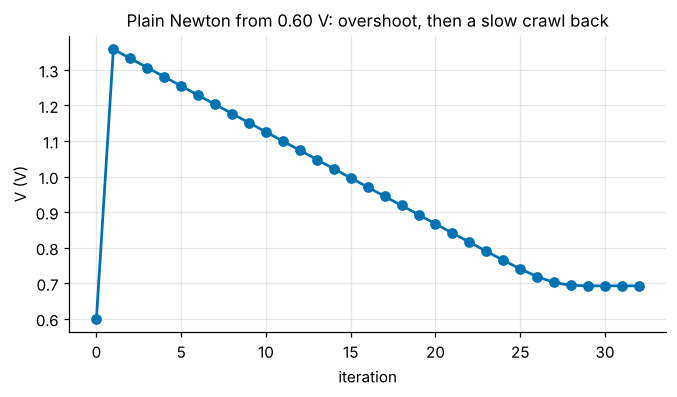

In [4]:
Is, VT = 1e-14, 0.025852

def g(V):  return (5 - V) / 1e3 - Is * math.expm1(V / VT)
def dg(V): return -1 / 1e3 - Is / VT * math.exp(V / VT)

def newton(V0, tol=1e-9, max_iter=100):
    history = [V0]
    for _ in range(max_iter):
        V = history[-1] - g(history[-1]) / dg(history[-1])
        history.append(V)
        if abs(history[-1] - history[-2]) < tol:
            break
    return history

for V0 in (0.70, 0.60):
    h = newton(V0)
    print(f"start {V0:.2f} V: {len(h) - 1} iterations -> V_D = {h[-1]:.7f} V; first iterates {np.round(h[1:4], 5)}")
h06 = newton(0.60)
plt.figure(figsize=(7, 3.5)); plt.plot(h06, "o-"); plt.xlabel("iteration"); plt.ylabel("V (V)")
plt.title("Plain Newton from 0.60 V: overshoot, then a slow crawl back"); plt.show()
assert len(newton(0.70)) - 1 == 5 and len(h06) - 1 == 32

## Part 3 — Run the tools from Python (optional, if installed)

In [5]:
if shutil.which("ngspice"):
    for cir in ["divider.cir", "rc_ac.cir"]:
        out = subprocess.run(["ngspice", "-b", cir], capture_output=True, text=True).stdout
        lines = [l.strip() for l in out.splitlines()
                 if "=" in l and l.split("=")[0].strip() in ("vout", "isrc", "vtypo", "vb4", "f3db_1", "f3db_2", "db_10k_2")]
        print(f"== {cir}"); print("\n".join("   " + l for l in lines))
else:
    print("ngspice not found; skipping.")
if shutil.which("iverilog"):
    subprocess.run(["iverilog", "-g2012", "-o", "mux2.vvp", "mux2_tb.v", "mux2.v"], check=True)
    print(subprocess.run(["vvp", "-n", "mux2.vvp"], capture_output=True, text=True).stdout)
    Path("mux2.vvp").unlink(missing_ok=True)
else:
    print("iverilog not found; skipping.")

== divider.cir
   vout = 2
   isrc = -0.001
   vtypo = 5
   vb4 = 2.5
== rc_ac.cir
   f3db_1              =  1.591549e+02
   f3db_2              =  1.591549e+03
   db_10k_2            =  -1.607224e+01
VCD info: dumpfile mux2_tb.vcd opened for output.
Checked 8 vectors, 0 errors
TEST PASSED
mux2_tb.v:27: $finish called at 8000 (1ps)

